
## Using Quantum-Selected Configuration Interaction with AMDs GPUs

In this notebook we will show you how to split the workloads of a hybrid algorithm between **IQM's QPUs** and **AMD's GPUs**, with the example of **Quantum-Selected Configuration Interaction (QSCI)**.


QSCI is a powerful hybrid quantum-classical algorithm designed to accurately compute molecular ground-state energies. Here, we'll explain the basics of the technique behind QSCI, how it works, and how you can leverage it to run meaningful quantum chemistry workloads on today's quantum hardware.

QSCI splits the problem across two worlds. A quantum computer samples the most physically relevant electron configurations from an exponentially large space, while a classical HPC backend performs the heavy diagonalization on the compressed subspace the quantum device identifies. 

In this notebook, you will learn how to

* ... set up a canonical QSCI workflow

* ... split it into Quantum Sampling with Qiskit and classical diagonalization with [JAX](https://docs.jax.dev/en/latest/index.html) 

* ... connect to the QPU for Quantum Sampling

* ... connect to the AMD GPU for classical diagonalization


Let us provide a breakdown of how the algorithm works:

QSCI tackles the problem of computing the ground-state energy of a molecule, the state in which electrons are arranged as stably as possible. Almost every chemically and physically relevant property of a molecule can be derived from or connected to it. It is useful in *drug discovery*, *molecular design*, *material design*, and many other fields.

**Why it's hard**: Because electrons interact with each other quantum mechanically, the exact ground-state energy cannot be computed efficiently on classical hardware beyond a few dozen electrons. The role of the quantum computer is to make the intractable part tractable.

Let us look at the math - starting from the **time-independent Schrödinger equation**: $\hat{H} |\Psi\rangle = E |\Psi\rangle$, where $\hat{H}$ is the molecular Hamiltonian, $|\Psi\rangle$ is the wavefunction, and $E$ is the corresponding energy eigenvalue. The ground-state energy $E_0$ is the smallest eigenvalue: $E_0 = \min_{|\Psi\rangle} \frac{\langle \Psi | \hat{H} | \Psi \rangle}{\langle \Psi | \Psi \rangle}$.

Now, to find such a ground state energy, one can diagonalize the Hamiltonian in the basis of Slater determinants $|\Phi_i\rangle$, such that $|\Psi_0\rangle = \sum_i c_i |\Phi_i\rangle$

Exact diagonalization requires all $2^N$ determinants, where $N$ is the number of electrons — that is, we are diagonalizing a $2^N \times 2^N$ matrix, which is exponentially intractable. Using the variational principle, QSCI instead selects a small subset $\mathcal{S}$ of the most relevant determinants, sampled by the quantum computer, and diagonalizes the projected Hamiltonian: $H_{ij}^\mathcal{S} = \langle \Phi_i | \hat{H} | \Phi_j \rangle, \, \, i,j \in \mathcal{S}$

The ground-state energy estimate is then the smallest eigenvalue of this reduced matrix:

$$E_0^\text{QSCI} = \lambda_\text{min}(H^\mathcal{S})$$

The workflow then looks as follows:

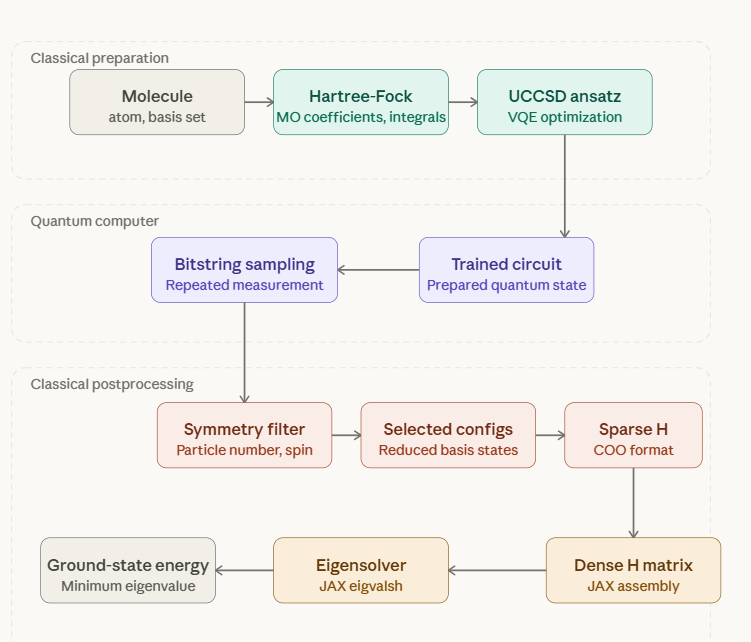

In [1]:
from IPython.display import Image, display
display(Image(filename="qsci_workflow.png"))

##### Classical preparation

In the classical preparation part we start by looking at a molecule. We define the atomic geometry and basis set that describes the problem. We run a mean-field Restricted Hartree-Fock (RHF) calculation to obtain the molecular orbital coefficients and one- and two-electron integrals. Then, we build a parameterized quantum circuit, namely a unitary coupled-cluster with singles and doubles (UCCSD) ansatz, on top of the HF state, systematically introducing electron correlation through single and double excitations.

#####  Quantum computer

On the Quantum computer, we variationally optimize the UCCSD parameters. 
The trained circuit is then used to sample bitstrings and produce a histogram of measured electron configurations.

##### Classical postprocessing
We then have to perform classical postprocessing, which begins by filtering out unphysical measurement outcomes. From these, the most frequently sampled valid configurations are selected to form
the reduced basis for the Hamiltonian. We then construct the many-body Hamiltonian restricted to this subspace, storing it in sparse coordinate or COO format. Finally, we diagonalize the Hermitian matrix using JAX's `eigvalsh` and return its smallest
eigenvalue as the QSCI estimate of the molecular ground-state energy.

#### Offloading the classical part to GPU: 

The massive postprocessing pipeline can completely be offloaded to AMD's GPUs. How? Great Question! 

We use [AMD Developer Cloud](https://amd.digitalocean.com/) hosted on **DigitalOcean** to create a Virtual Machine (referred to as an AMD GPU droplet) that serves as the execution backend for the whole code in this tutorial, which with the correct setup, will connect to IQM Resonance for the quantum computations and use and AMD GPUs for the classical computations.

#### Creating a droplet

Assuming that you already have an account (if not you can create one at [AMD's DigitalOcean instance](https://amd.digitalocean.com/login)), you will need to create a new droplet. A droplet is the DigitalOcean term for a virtual machine. 
You can then set up this droplet to be used as the interpreter in an ``ipynb`` Python notebook in VS Code, which is the recommended way of setting this up. For registering a droplet as an interpreter in VS Code please refer to the [tutorial provided by AMD](https://www.digitalocean.com/community/tutorials/jupyter-notebooks-with-gpu-droplets)

#### Setting up the droplet for this tutorial

There is some setup required for the droplet to be able interpret the code in this tutorial. You can find the necessary steps at the bottom of this document in the ``amd_gpu_droplet_setup.md`` Markdown file.

**Disclaimer**: to run the code associated to this notebook, you don't necessarily need to have a GPU available. You can run this notebook out of the box and set up the GPU connection when you have credit available.

### Implementing the QSCI workflow

Lets get started with coding!

First, we import all the things relevant for the classical computations - JAX and pyscf. The latter is used for everything chemistry related. 

We use [JAX](https://docs.jax.dev/en/latest/index.html) to interface with the AMD GPU. It has experimental ROCm support, and with some minor tweaks will do all the classical postprocesing leveraging parallelization. 

In [2]:
from functools import reduce
import numpy as np      # keep for PySCF boundary
import jax.numpy as jnp # replace for GPU
from jax import config
import jax.scipy.linalg as jsla
from jax.experimental.sparse import BCSR  # JAX sparse format
from pyscf import ao2mo, gto, scf
from __future__ import annotations

config.update("jax_enable_x64", True)

Addtionally we need to import qiskit and specific functionalities to perform the quantum routines.

In [3]:
from qiskit import QuantumCircuit, qpy, transpile
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer import AerSimulator # incase you want sample locally
from qiskit_aer.primitives import Estimator
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import L_BFGS_B

from qiskit_algorithms import NumPyMinimumEigensolver
from qiskit_nature.second_q.algorithms import GroundStateEigensolver
from qiskit_nature.second_q.circuit.library import HartreeFock, UCCSD
from qiskit_nature.second_q.mappers import JordanWignerMapper
from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.second_q.operators import SparseLabelOp

ModuleNotFoundError: No module named 'qiskit_algorithms'

#### Preparing the Variational Ansatz for QSCI

Let's get our hands dirty! 

Before the quantum computer can sample electron configurations, it needs a circuit that approximates the target electronic state. We will create a function `prepare_ansatz` that constructs and variationally optimizes this circuit, producing the trained quantum state that QSCI will then sample from.

The function takes as inputs:

- `num_spatial_orbitals`: Number of spatial orbitals
- `num_particles`: Number of particles
- `operator`: The fermionic operator to be mapped and minimized
- `offload`: Whether to dispatch the optimization to IQM's quantum hardware

1. We start by mapping the fermionic Hamiltonian to qubit space with ``JordanWignerMapper``([docs](https://qiskit-community.github.io/qiskit-nature/stubs/qiskit_nature.second_q.mappers.JordanWignerMapper.html)). The electronic Hamiltonian is defined in fermionic language, but quantum computers operate on qubits — the Jordan-Wigner mapper translates fermionic creation and annihilation operators into qubit Pauli operators.

2. The circuit is then seeded with the ``HartreeFock``([docs](https://qiskit-community.github.io/qiskit-nature/stubs/qiskit_nature.second_q.circuit.library.HartreeFock.html)) state — the mean-field approximation of the ground state. This gives the variational optimizer a physically meaningful starting point, rather than an arbitrary superposition.

3. A *Unitary Coupled Cluster Singles and Doubles* ``UCCSD``([docs](https://qiskit-community.github.io/qiskit-nature/stubs/qiskit_nature.second_q.circuit.library.UCCSD.html)) circuit is layered on top of the Hartree-Fock initial state. UCCSD introduces electron correlation by parameterizing single and double excitations.

4. The target operator is then mapped from fermionic to qubit representation using the ``JordanWignerMapper().map``. This produces the observable that the estimator will evaluate during optimization.

5. The ansatz parameters are optimized by minimizing the energy expectation value, using ``VQE``, with the ``L_BFGS_B`` optimizer. You can find the respective code at the end of the document in the ``estimate_iqm`` function. Depending on whether you set the `offload` flag ``True`` or ``False``, this runs either locally or is dispatched to IQM's quantum hardware. 

6. Once optimal parameters are found, they are bound to the ansatz circuit. This is the circuit QSCI will execute on the quantum computer to sample the most relevant electron configurations.


In [ ]:
def prepare_ansatz(
    num_spatial_orbitals: int,
    num_particles: int,
    operator: SparseLabelOp,
    offload: bool = False
) -> QuantumCircuit:
    """Prepare Ansatz for QSCI using Estimator.

    Args:
        num_spatial_orbitals: Number of spatial orbitals.
        num_particles: Number of particles.
        operator: Operator to be used in the estimator.
        offload: Whether to offload the estimation to the real quantum computer.

    Returns:
        QuantumCircuit: Trained ansatz circuit.
    """
    # 1. Use Jordan Wigner qubit mapping
    mapper = JordanWignerMapper()

    # 2. Generate a HF ansatz
    initial_state = HartreeFock(
        num_spatial_orbitals,
        num_particles,
        mapper,
    )

    # 3. Generate UCCSD circuit
    ansatz = UCCSD(
        num_spatial_orbitals,
        num_particles,
        mapper,
        initial_state=initial_state,
    )

    # 4. Get the observable 
    observable = mapper.map(operator)

    # 5. Choose the estimation method based on the offload flag
    if offload:
        optimal_params = estimate_iqm(
            ansatz,
            observable,
            maxiter=80,
        )
        
    else:
        optimal_params = estimate_local(ansatz, observable, maxiter=80)

    # 6. Return the trained ansatz circuit
    ansatz_circuit = ansatz.assign_parameters(optimal_params)
    ansatz_circuit.measure_all()
    return ansatz_circuit



#### Postprocessing Quantum Samples to Compute the Ground-State Energy

After setting up our quantum routine, we can now build the postprocessing pipeline called ``postprocess_gpu``. 
It takes the raw measurement counts from the quantum computer, filters physically valid states, builds the molecular Hamiltonian, and returns the minimum eigenvalue — the ground-state energy estimate.

Importantly, if you are running this code on an AMD droplet, then the GPU acceleration will happen automatically. If you are not, the code will run without GPU acceleration.

It feeds into the helper function ``_full_mbh_canonical_from_qsci`` for computing the reduced Hamiltonian, which you can find attached in the Appendix of this tutorial, see the ``_full_mbh`` file

Let us break it down into 7 steps: 

1. We order the histogram of measured bitstring states ``counts``, which we received from the quantum computer,  into ``basis_counts``. They are sorted by how often they were sampled, with higher counts indicating more physically relevant configurations.
2. We then gather all states that are physically valid. Only states with the correct total electron count and equal spin-up/spin-down occupancy are kept, see the corresponding ``if``- statement

Then a few chemistry related calculations are undertaken, including
3. a Restricted Hartree-Fock (RHF) calculation to obtain the molecular orbital coefficients and one- and two-electron integrals,
4. a rotation of the one-electron integrals ``h1_ortho`` and two-electron integrals ``h2_ortho`` from the atomic orbital basis into the molecular orbital basis,
5. and splitting the Hamiltonian into its diagonal (on-site energies) and off-diagonal (hopping) parts.

6. Using the function ``_full_mbh_canonical_from_qsci`` we then construct the many-body Hamiltonian restricted to the QSCI-selected configuration subspace.

7. We then assemble a dense JAX matrix to use JAX's GPU accelerated [``eigvalsh``](https://docs.jax.dev/en/latest/_autosummary/jax.numpy.linalg.eigvalsh.html#jax.numpy.linalg.eigvalsh) for diagonalization. 

The diagonalized Hermitian matrix'  eigenvalues are returned in ascending order. The first eigenvalue is the ground-state energy, the QSCI estimate of the molecular ground state, and the desired result of our calculation!

In [ ]:

def postprocess_gpu(
    atom: str, basis: str, counts: dict[str, int], cutoff: int = 10
) -> float:
    """Postprocess the results from the quantum computer and compute the minimum eigenvalue using AMD GPUs.

    Args:
        atom: The molecule structure
        basis: The basis set for the molecule
        counts: The sampled states from the quantum computer
        cutoff: The maximum number of states to consider for the reduced basis

    Returns:
        The minimum eigenvalue of the reduced Hamiltonian based on QSCI.
    """
    basis_states = list(counts.keys())
    basis_counts = list(counts.values())
    num_qubits = len(basis_states[0])

    # 1. Sort the bitstrings by number of samples
    sorted_idx = jnp.argsort(jnp.array(basis_counts))[::-1]  # typecast jax
    threshold = min(cutoff, len(basis_states))
    selected_states = []

    for idx in sorted_idx:
        state = basis_states[idx]
        # 2. Keep only physically valid configs
        if state.count("1") == num_qubits // 2 and (
            state[: num_qubits // 2].count("1") == state[num_qubits // 2 :].count("1")
        ):
            selected_states.append(int(state, 2))
            if len(selected_states) >= threshold:
                break

    if len(selected_states) < 2:
        raise ValueError(
            "Not enough states selected for the Hamiltonian. Something went wrong."
        )

    
    # 3. Restricted Hartree-Fock calculation
    mol = gto.Mole(verbose=0) # verbose=3
    mol.build(atom=atom, basis=basis)
    mf = scf.RHF(mol)
    mf.kernel()
    mf._eri = mf.mol.intor('int2e')  # explicitly compute and store integrals
    h1 = mf.get_hcore()
    mo = mf.mo_coeff
    h1 = jnp.array(h1) # Cast PySCF numpy outputs to JAX at the boundary
    mo = jnp.array(mo)

    # 4. Rotation of the electron integrals 
    h1_ortho = reduce(jnp.dot, (mo.conj().T, h1, mo))
    h2_ortho = ao2mo.kernel(mf._eri, np.array(mo, dtype=np.float64)) 

    # 5. splitting the Hamiltonian into diagonal and off-diagonal part
    h_diag = jnp.diag(h1_ortho)
    h_diag = jnp.kron(jnp.array([1, 1]), h_diag)
    h_offdiag = h1_ortho - jnp.diag(jnp.diag(h1_ortho))

    h2 = ao2mo.restore(1, 
                        h2_ortho, 
                        mol.nao)  
    h2 = jnp.array(h2) # typecast for jax functionality


    # 6. construct Hamiltonian restricted to selected configuration subspace
    r, c, v = _full_mbh_canonical_from_qsci(
        selected_states, h_diag, h_offdiag, h2, num_qubits, 1e-4
    )

    # 7.Assemble dense matrix and use JAX to calculate eigenvalue
    n = len(selected_states)
    hr = jnp.zeros((n, n), dtype=jnp.complex128)
    hr = hr.at[jnp.array(r), jnp.array(c)].set(jnp.array(v)) 
    
    # Get the smallest eigenvalue of the Hamiltonian using JAX
    eigvals = jnp.linalg.eigvalsh(hr)  
    
    return float(eigvals[0])
    




With all building blocks in place, we can now wire everything together into a single end-to-end workflow via `run_qsci`. This function runs the full QSCI algorithm, from molecule definition to ground-state energy.

The function takes as inputs:

- `atom`: Atomic configuration of the molecule (e.g. `"H 0 0 0; H 0 0 1;"`)
- `basis`: Basis set for the quantum chemistry calculation (e.g. `"sto-3g"`)
- `offload`: Whether to dispatch the quantum execution to IQM's hardware via Resonance

Let's walk through what happens end-to-end.

1. The molecule is defined and passed to `PySCFDriver`([docs](https://qiskit-community.github.io/qiskit-nature/stubs/qiskit_nature.second_q.drivers.PySCFDriver.html)), which sets up the quantum chemistry problem, including the nuclear repulsion energy, which will be added back to the electronic energy at the end.

2. `prepare_ansatz` is called to construct and variationally optimize the UCCSD circuit for the given molecule, producing the trained quantum state ready for sampling.

3. The ansatz circuit is sampled, either on IQM's quantum hardware via `sample_iqm` or locally via `sample_local` (see bottom of the document for the util functions) producing the measured bitstrings `counts`.

4. `postprocess_gpu` takes the measurement counts and, using a GPU-accelerated calculation if you are running the code on an AMD droplet, returns the minimum eigenvalue of the reduced Hamiltonian, as explained above.

5. We return the ``eigenval`` and ``nuclear_repulsion_energy`` as the result of the algorithm.

We test this on the simplest possible molecule, the hydrogen dimer H₂ in a minimal `sto-3g` basis, as a sanity check of the full pipeline before scaling to larger systems.
Adding the ``eigenval`` and ``nuclear_repulsion_energy`` provides our final solution. 


In [ ]:
"""Tests for performing the full QSCI algorithm on the Hybrid Demonstrator."""

from iqm.qiskit_iqm import IQMProvider

my_token= input()

provider = IQMProvider("https://resonance.meetiqm.com/garnet",
            token=my_token)

def run_qsci(
    atom: str, basis: str, offload: bool
) -> None:
    """
    Helper function to run QSCI tests.

    Args:
        atom (str): Atomic configuration of the molecule.
        basis (str): Basis set for the quantum chemistry calculation.
        offload (bool): Whether to offload the computation to the IQM Resonance Quantum Computer.
        
    """
    driver = PySCFDriver(atom=atom, basis=basis)
    problem = driver.run()
    nuclear_repulsion_energy = problem.nuclear_repulsion_energy

    ansatz_circ = prepare_ansatz(
        problem.num_spatial_orbitals,
        problem.num_particles,
        problem.second_q_ops()[0],
        offload=offload
        
    )

    if offload:
        counts = sample_iqm(ansatz_circ, shots=100)
    else:
        counts = sample_local(ansatz_circ, shots=10000)

    postprocess_func = postprocess_gpu 
    eigval = postprocess_func(atom, basis, counts)
    

    return eigval, nuclear_repulsion_energy
    
    



That was a lot of setup, which is unfortunately necessary. Now we get to the fun part - actually running the algorithm! 
Lets run it on a simulator first. 

In [ ]:
atom="H 0 0 0; H 0 0 1;"
basis="sto-3g"

eigval, nuclear_repulsion_energy = run_qsci(atom=atom, basis=basis, offload=False)

print(f"QSCI result simulated  = {eigval + nuclear_repulsion_energy:.15f}")

Is the simulator results satisfactory? The expected result should be ``-1.101...``
And now, lets run it on real hardware! 

In [ ]:
atom="H 0 0 0; H 0 0 1;"
basis="sto-3g"

eigval, nuclear_repulsion_energy = run_qsci(atom=atom, basis=basis, offload=True)

print(f"QSCI result IQM Resonance  = {eigval + nuclear_repulsion_energy:.15f}")

That's it! You have now executed the whole QSCI workflow, with the Quantum part offloaded to IQM's QPUs via the *IQM Resonance* cloud platform, and the classical postprocessing offloaded to AMD's GPUs via their *DigitalOcean* cloud offering! 

To verify our QSCI result, we benchmark it against an exact classical solution. `NumPyMinimumEigensolver`([docs](https://qiskit-community.github.io/qiskit-algorithms/stubs/qiskit_algorithms.NumPyMinimumEigensolver.html)) performs exact full configuration interaction (FCI) diagonalization, making it and ideal check for our small system QSCI estimate. We reinitialise ``PySCFDriver`` with the same molecule and basis set, and, using the ``GroundStateEigensolver``([docs](https://qiskit-community.github.io/qiskit-nature/tutorials/03_ground_state_solvers.html)) find an exact solution to our problem, which is printed alongside an exact reference computed via `NumPyMinimumEigensolver`. **Attention!** This version of the `NumPyMinimumEigensolver` is bugged. You will need to adjust the source code to fix a SciPy related bug in `qiskit-algorithms 0.2.2`. Find the fix in the ``amd_gpu_droplet_setup.md`` guide in the Appendix (Step 8. Fix qiskit-algorithms Scipy Compatibility Bug). 

How does the algorithm perform? You may need to run multiple iterations to receive at the desired accuracy. 

In [ ]:
driver = PySCFDriver(atom=atom, basis=basis)
problem = driver.run()
mapper = JordanWignerMapper()
solver = GroundStateEigensolver(mapper, NumPyMinimumEigensolver())
exact_gs_energy = solver.solve(problem).total_energies[0]

exact_gs_energy = solver.solve(problem).total_energies[0]
print(f"Exact result = {exact_gs_energy:.15f}")

assert abs(exact_gs_energy - eigval - nuclear_repulsion_energy) < 1e-3

#### Methodology review

The variational principle guarantees that the QSCI estimate is always an upper bound on the true ground-state energy. The gap to the exact solution depends on how much of the true wavefunction lives outside the sampled subspace, which degrades with a weak ansatz, too few shots, or hardware noise. Increasing ``cutoff`` improves subspace quality but grows diagonalization cost proportional to $|\mathcal{S}|^3$. So the GPU acceleration is doing real work here. 
Finally, note that for $H_2$ in ``STO-3G`` the full Hilbert space has only dimension 6. Our benchmark therefore only validates the pipeline. If you mention to scale to 8+ qubits you will see QSCI earn its keep.

#### Token disclaimer

With **100 shots** in each VQE iteration (this can be adjusted in ``estimate_iqm`` helper function in the appendix) and **100 shots** in the full sampling (see the argument given to ``sample_iqm`` in the ``run_qsci`` main routine), this notebook costs about 45 credits to run on IQM Garnet.

#### Take it further! 

Now it's your turn. Start from the code above. Extend the solution to more difficult molecules! How much can the hardware handle? Will you hit the breaking point of 8+ qubits? Share your results with us! 

In [ ]:
# Copyright 2026 IQM Quantum Computers (Niklas Steinmann, Daniel Bulmash)
#
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
#     http://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.